### Heart Disease Classification: Exploratory Data Analysis and Preprocessing

#### Project objective

The objective of this project is to build an end-to-end MLOps pipeline for predicting the presence or absence of heart disease using patient clinical attributes.

This notebook covers:

- Reproducible dataset acquisition
- Initial data inspection
- Data-quality assessment
- Missing-value identification
- Target transformation
- Duplicate handling
- Exploratory data analysis
- Class-balance analysis
- Numerical and categorical feature analysis
- Correlation analysis
- Creation of a cleaned dataset for model development

#### Dataset

The project uses the Heart Disease dataset from the UCI Machine Learning Repository. The Cleveland subset contains 303 observations, 13 predictor variables, and one diagnosis target.

The original target ranges from 0 to 4:

- `0`: No presence of heart disease
- `1–4`: Presence of heart disease

For this project, the target is converted into a binary classification variable:

- `0`: No heart disease
- `1`: Heart disease present

#### Educational-use notice

This project is intended only to demonstrate machine learning and MLOps practices. It is not a clinical diagnostic system and should not be used to make medical decisions.

In [2]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)
pd.set_option("display.float_format", lambda value: f"{value:.3f}")

sns.set_theme(style="whitegrid", context="notebook")

RANDOM_STATE = 42

print("Libraries imported successfully.")

Libraries imported successfully.


In [3]:
def find_project_root(start_path: Path) -> Path:
    """Locate the repository root by searching for the .git directory."""
    current_path = start_path.resolve()

    for candidate in [current_path, *current_path.parents]:
        if (candidate / ".git").exists():
            return candidate

    raise FileNotFoundError(
        "Repository root could not be found. "
        "Open this notebook from inside the GitHub repository."
    )


PROJECT_ROOT = find_project_root(Path.cwd())

RAW_DATA_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DATA_DIR = PROJECT_ROOT / "data" / "processed"
FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"

RAW_DATA_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DATA_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

RAW_DATA_PATH = RAW_DATA_DIR / "heart_disease_uci_original.csv"
PROCESSED_DATA_PATH = PROCESSED_DATA_DIR / "heart_disease_cleaned.csv"

print(f"Project root: {PROJECT_ROOT}")
print(f"Raw data directory: {RAW_DATA_DIR}")
print(f"Processed data directory: {PROCESSED_DATA_DIR}")
print(f"Figures directory: {FIGURES_DIR}")

Project root: /workspaces/MLOPS_Assignment
Raw data directory: /workspaces/MLOPS_Assignment/data/raw
Processed data directory: /workspaces/MLOPS_Assignment/data/processed
Figures directory: /workspaces/MLOPS_Assignment/reports/figures


#### 1. Dataset acquisition

The dataset is retrieved programmatically from the UCI Machine Learning Repository using its dataset identifier. Programmatic acquisition improves reproducibility because another user can rerun the notebook without manually locating or modifying a CSV file.

The original features and original diagnosis target are retained in the raw-data directory before subsequent cleaning and target transformation.

In [4]:
heart_disease = fetch_ucirepo(id=45)

X_original = heart_disease.data.features.copy()
y_original = heart_disease.data.targets.copy()

print("Feature shape:", X_original.shape)
print("Target shape:", y_original.shape)
print("\nFeature columns:")
print(X_original.columns.tolist())
print("\nTarget columns:")
print(y_original.columns.tolist())

Feature shape: (303, 13)
Target shape: (303, 1)

Feature columns:
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal']

Target columns:
['num']


In [5]:
raw_df = pd.concat(
    [
        X_original.reset_index(drop=True),
        y_original.reset_index(drop=True),
    ],
    axis=1,
)

# Standardize target-column name before saving.
if "num" in raw_df.columns:
    raw_df = raw_df.rename(columns={"num": "original_target"})
elif "target" in raw_df.columns:
    raw_df = raw_df.rename(columns={"target": "original_target"})
else:
    raw_df = raw_df.rename(
        columns={raw_df.columns[-1]: "original_target"}
    )

raw_df.to_csv(RAW_DATA_PATH, index=False)

print(f"Original data saved to: {RAW_DATA_PATH}")
print("Dataset shape:", raw_df.shape)

raw_df.head()

Original data saved to: /workspaces/MLOPS_Assignment/data/raw/heart_disease_uci_original.csv
Dataset shape: (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,original_target
0,63,1,1,145,233,1,2,150,0,2.300,3,0.000,6.000,0
1,67,1,4,160,286,0,2,108,1,1.500,2,3.000,3.000,2
2,67,1,4,120,229,0,2,129,1,2.600,2,2.000,7.000,1
3,37,1,3,130,250,0,0,187,0,3.500,3,0.000,3.000,0
4,41,0,2,130,204,0,2,172,0,1.400,1,0.000,3.000,0


#### 2. Initial data inspection

Initial inspection is performed to understand the dataset structure, column types, descriptive statistics, unique values, duplicate records, and missing-value patterns before preprocessing.

In [6]:
print("Dataset dimensions:", raw_df.shape)

display(raw_df.head())

print("\nColumn data types:")
display(raw_df.dtypes.to_frame(name="data_type"))

print("\nDataset information:")
raw_df.info()

Dataset dimensions: (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,original_target
0,63,1,1,145,233,1,2,150,0,2.300,3,0.000,6.000,0
1,67,1,4,160,286,0,2,108,1,1.500,2,3.000,3.000,2
2,67,1,4,120,229,0,2,129,1,2.600,2,2.000,7.000,1
3,37,1,3,130,250,0,0,187,0,3.500,3,0.000,3.000,0
4,41,0,2,130,204,0,2,172,0,1.400,1,0.000,3.000,0



Column data types:


,data_type
age,int64
sex,int64
cp,int64
trestbps,int64
chol,int64
fbs,int64
restecg,int64
thalach,int64
exang,int64
oldpeak,float64



Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   age              303 non-null    int64  
 1   sex              303 non-null    int64  
 2   cp               303 non-null    int64  
 3   trestbps         303 non-null    int64  
 4   chol             303 non-null    int64  
 5   fbs              303 non-null    int64  
 6   restecg          303 non-null    int64  
 7   thalach          303 non-null    int64  
 8   exang            303 non-null    int64  
 9   oldpeak          303 non-null    float64
 10  slope            303 non-null    int64  
 11  ca               299 non-null    float64
 12  thal             301 non-null    float64
 13  original_target  303 non-null    int64  
dtypes: float64(3), int64(11)
memory usage: 33.3 KB


In [7]:
display(raw_df.describe(include="all").T)

,count,mean,std,min,25%,50%,75%,max
age,303.000,54.439,9.039,29.000,48.000,56.000,61.000,77.000
sex,303.000,0.680,0.467,0.000,0.000,1.000,1.000,1.000
cp,303.000,3.158,0.960,1.000,3.000,3.000,4.000,4.000
trestbps,303.000,131.690,17.600,94.000,120.000,130.000,140.000,200.000
chol,303.000,246.693,51.777,126.000,211.000,241.000,275.000,564.000
fbs,303.000,0.149,0.356,0.000,0.000,0.000,0.000,1.000
restecg,303.000,0.990,0.995,0.000,0.000,1.000,2.000,2.000
thalach,303.000,149.607,22.875,71.000,133.500,153.000,166.000,202.000
exang,303.000,0.327,0.470,0.000,0.000,0.000,1.000,1.000
oldpeak,303.000,1.040,1.161,0.000,0.000,0.800,1.600,6.200


In [8]:
unique_summary = pd.DataFrame(
    {
        "data_type": raw_df.dtypes.astype(str),
        "unique_value_count": raw_df.nunique(dropna=True),
        "missing_value_count": raw_df.isna().sum(),
    }
)

display(unique_summary)

,data_type,unique_value_count,missing_value_count
age,int64,41,0
sex,int64,2,0
cp,int64,4,0
trestbps,int64,50,0
chol,int64,152,0
fbs,int64,2,0
restecg,int64,3,0
thalach,int64,91,0
exang,int64,2,0
oldpeak,float64,40,0


In [9]:
categorical_candidates = [
    "sex",
    "cp",
    "fbs",
    "restecg",
    "exang",
    "slope",
    "ca",
    "thal",
    "original_target",
]

for column in categorical_candidates:
    if column in raw_df.columns:
        values = sorted(raw_df[column].dropna().unique().tolist())
        print(f"{column}: {values}")

sex: [0, 1]
cp: [1, 2, 3, 4]
fbs: [0, 1]
restecg: [0, 1, 2]
exang: [0, 1]
slope: [1, 2, 3]
ca: [0.0, 1.0, 2.0, 3.0]
thal: [3.0, 6.0, 7.0]
original_target: [0, 1, 2, 3, 4]


In [10]:
duplicate_count = raw_df.duplicated().sum()
duplicate_percentage = 100 * duplicate_count / len(raw_df)

print(f"Number of exact duplicate rows: {duplicate_count}")
print(f"Percentage of duplicate rows: {duplicate_percentage:.2f}%")

Number of exact duplicate rows: 0
Percentage of duplicate rows: 0.00%


#### 3. Data cleaning and target preparation

The following cleaning operations are performed:

1. Column names are standardized.
2. Placeholder missing-value markers are converted to actual null values.
3. Columns are converted to numeric data types.
4. Exact duplicate records are removed.
5. The original diagnosis target is converted to a binary target.
6. Predictors with missing values are left unimputed at this stage.

Missing-value imputation will be fitted only on the training data inside the machine-learning pipeline. This prevents information from the test set from influencing preprocessing.

In [11]:
clean_df = raw_df.copy()

# Standardize column names.
clean_df.columns = (
    clean_df.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
)

# Convert common placeholder values to proper missing values.
missing_markers = ["?", "NA", "N/A", "null", "None", ""]
clean_df = clean_df.replace(missing_markers, np.nan)

# Convert all columns to numeric format.
for column in clean_df.columns:
    clean_df[column] = pd.to_numeric(
        clean_df[column],
        errors="coerce",
    )

rows_before_duplicate_removal = len(clean_df)

clean_df = (
    clean_df
    .drop_duplicates()
    .reset_index(drop=True)
)

rows_after_duplicate_removal = len(clean_df)

# Create binary target:
# 0 remains 0, while values 1–4 become 1.
clean_df["target"] = (
    clean_df["original_target"] > 0
).astype(int)

# The original multiclass diagnosis is no longer used as a model feature.
clean_df = clean_df.drop(columns=["original_target"])

print(
    "Rows removed as exact duplicates:",
    rows_before_duplicate_removal - rows_after_duplicate_removal,
)

print("Cleaned dataset shape:", clean_df.shape)

display(clean_df.head())

Rows removed as exact duplicates: 0
Cleaned dataset shape: (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,1,145,233,1,2,150,0,2.300,3,0.000,6.000,0
1,67,1,4,160,286,0,2,108,1,1.500,2,3.000,3.000,1
2,67,1,4,120,229,0,2,129,1,2.600,2,2.000,7.000,1
3,37,1,3,130,250,0,0,187,0,3.500,3,0.000,3.000,0
4,41,0,2,130,204,0,2,172,0,1.400,1,0.000,3.000,0


In [12]:
expected_columns = [
    "age",
    "sex",
    "cp",
    "trestbps",
    "chol",
    "fbs",
    "restecg",
    "thalach",
    "exang",
    "oldpeak",
    "slope",
    "ca",
    "thal",
    "target",
]

missing_expected_columns = sorted(
    set(expected_columns) - set(clean_df.columns)
)

unexpected_columns = sorted(
    set(clean_df.columns) - set(expected_columns)
)

print("Missing expected columns:", missing_expected_columns)
print("Unexpected columns:", unexpected_columns)
print("Target values:", sorted(clean_df["target"].unique().tolist()))
print("Target contains missing values:", clean_df["target"].isna().any())
print("Remaining exact duplicates:", clean_df.duplicated().sum())

assert not missing_expected_columns, (
    f"Expected columns are missing: {missing_expected_columns}"
)

assert not unexpected_columns, (
    f"Unexpected columns were found: {unexpected_columns}"
)

assert set(clean_df["target"].unique()) <= {0, 1}, (
    "Target must contain only 0 and 1."
)

assert clean_df["target"].notna().all(), (
    "Target contains missing values."
)

print("\nAll data validation checks passed.")

Missing expected columns: []
Unexpected columns: []
Target values: [0, 1]
Target contains missing values: False
Remaining exact duplicates: 0

All data validation checks passed.


#### 4. Missing-value analysis

Missing values are identified before model development. They are not filled in this notebook because imputation must be included within the training pipeline and fitted only on the training portion of the data.

In [13]:
missing_summary = pd.DataFrame(
    {
        "missing_count": clean_df.isna().sum(),
        "missing_percentage": (
            clean_df.isna().mean() * 100
        ).round(2),
    }
)

missing_summary = (
    missing_summary[missing_summary["missing_count"] > 0]
    .sort_values("missing_count", ascending=False)
)

if missing_summary.empty:
    print("No missing values were detected.")
else:
    display(missing_summary)

,missing_count,missing_percentage
ca,4,1.320
thal,2,0.660


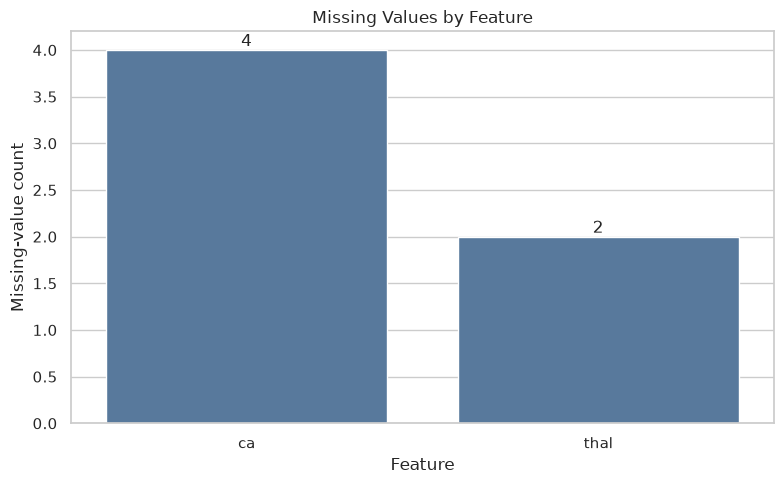

Figure saved to: /workspaces/MLOPS_Assignment/reports/figures/missing_values.png


In [14]:
if not missing_summary.empty:
    plt.figure(figsize=(8, 5))

    ax = sns.barplot(
        data=missing_summary.reset_index(),
        x="index",
        y="missing_count",
        color="#4C78A8",
    )

    plt.title("Missing Values by Feature")
    plt.xlabel("Feature")
    plt.ylabel("Missing-value count")

    for container in ax.containers:
        ax.bar_label(container)

    plt.tight_layout()

    missing_plot_path = FIGURES_DIR / "missing_values.png"
    plt.savefig(
        missing_plot_path,
        dpi=300,
        bbox_inches="tight",
    )

    plt.show()

    print(f"Figure saved to: {missing_plot_path}")
else:
    print("Missing-value chart was not required.")

##### Missing-value observation

The missing-value analysis indicates that missing observations are limited to a small number of predictor fields, primarily `ca` and `thal`. The target does not contain missing values.

The rows are retained because the missing proportion is small and removing complete records would unnecessarily reduce an already small dataset. During model training:

- Numerical missing values will be filled using median imputation.
- Categorical missing values will be filled using most-frequent imputation.
- Imputation will be included within the scikit-learn preprocessing pipeline.

In [15]:
target_labels = {
    0: "No heart disease",
    1: "Heart disease present",
}

target_counts = (
    clean_df["target"]
    .value_counts()
    .sort_index()
)

target_percentages = (
    clean_df["target"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
)

target_summary = pd.DataFrame(
    {
        "class_label": [
            target_labels[index]
            for index in target_counts.index
        ],
        "count": target_counts.values,
        "percentage": target_percentages.values.round(2),
    },
    index=target_counts.index,
)

target_summary.index.name = "target"

display(target_summary)

,class_label,count,percentage
target,,,
0,No heart disease,164,54.130
1,Heart disease present,139,45.870


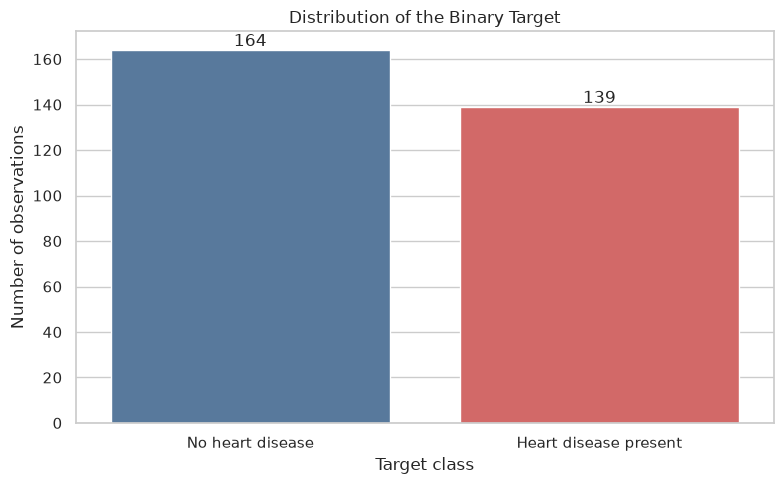

Figure saved to: /workspaces/MLOPS_Assignment/reports/figures/target_distribution.png


In [16]:
plot_target_df = clean_df.copy()
plot_target_df["target_label"] = (
    plot_target_df["target"].map(target_labels)
)

plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=plot_target_df,
    x="target_label",
    order=[
        "No heart disease",
        "Heart disease present",
    ],
    palette=["#4C78A8", "#E45756"],
)

plt.title("Distribution of the Binary Target")
plt.xlabel("Target class")
plt.ylabel("Number of observations")

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()

target_plot_path = FIGURES_DIR / "target_distribution.png"
plt.savefig(
    target_plot_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print(f"Figure saved to: {target_plot_path}")

In [17]:
minority_percentage = target_percentages.min()
majority_percentage = target_percentages.max()
class_ratio = target_counts.max() / target_counts.min()

print(f"Minority-class percentage: {minority_percentage:.2f}%")
print(f"Majority-class percentage: {majority_percentage:.2f}%")
print(f"Majority-to-minority ratio: {class_ratio:.2f}")

if class_ratio < 1.5:
    print(
        "Interpretation: The target is reasonably balanced. "
        "Stratified splitting will still be used."
    )
elif class_ratio < 3:
    print(
        "Interpretation: The target has moderate imbalance. "
        "Stratified splitting and class-weight tuning should be considered."
    )
else:
    print(
        "Interpretation: The target is substantially imbalanced. "
        "Accuracy alone would not be sufficient."
    )

Minority-class percentage: 45.87%
Majority-class percentage: 54.13%
Majority-to-minority ratio: 1.18
Interpretation: The target is reasonably balanced. Stratified splitting will still be used.


##### Target-distribution observation

The target contains both positive and negative cases in meaningful proportions. Therefore, the dataset is suitable for stratified train-test splitting and stratified cross-validation.

Model evaluation will not rely only on accuracy. Precision, recall, F1-score, ROC-AUC, confusion matrices, and ROC curves will also be used.

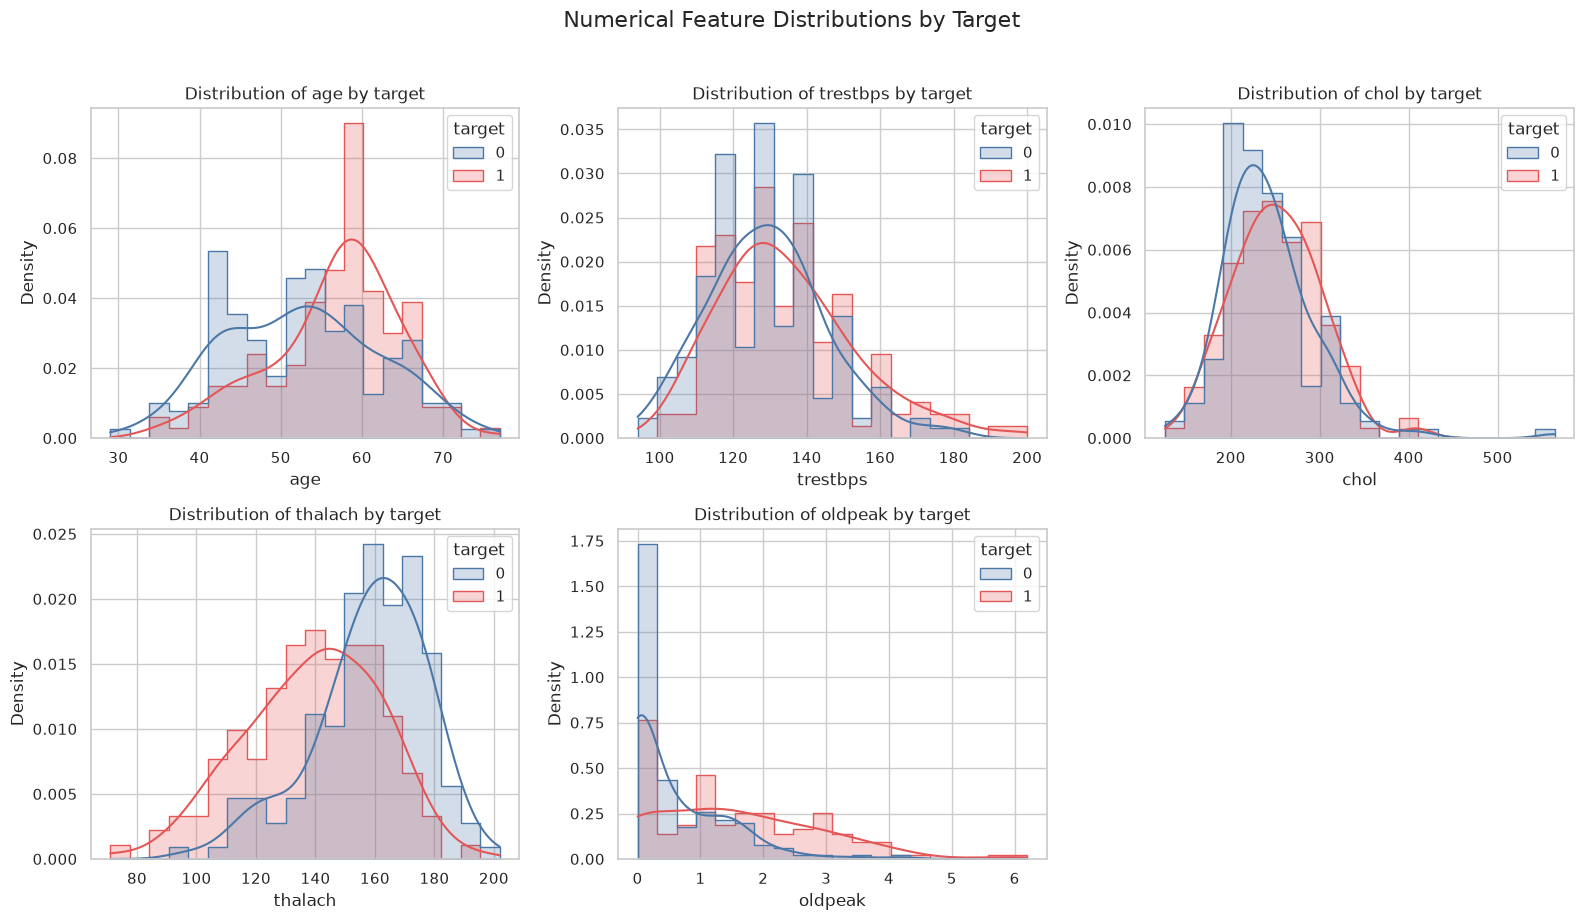

Figure saved to: /workspaces/MLOPS_Assignment/reports/figures/numerical_feature_distributions.png


In [18]:
numerical_features = [
    "age",
    "trestbps",
    "chol",
    "thalach",
    "oldpeak",
]

fig, axes = plt.subplots(
    nrows=2,
    ncols=3,
    figsize=(16, 9),
)

axes = axes.flatten()

for index, feature in enumerate(numerical_features):
    sns.histplot(
        data=clean_df,
        x=feature,
        hue="target",
        bins=20,
        kde=True,
        element="step",
        stat="density",
        common_norm=False,
        ax=axes[index],
        palette=["#4C78A8", "#E45756"],
    )

    axes[index].set_title(
        f"Distribution of {feature} by target"
    )
    axes[index].set_xlabel(feature)
    axes[index].set_ylabel("Density")

for unused_axis in axes[len(numerical_features):]:
    unused_axis.axis("off")

plt.suptitle(
    "Numerical Feature Distributions by Target",
    fontsize=16,
    y=1.02,
)

plt.tight_layout()

numerical_plot_path = (
    FIGURES_DIR / "numerical_feature_distributions.png"
)

plt.savefig(
    numerical_plot_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print(f"Figure saved to: {numerical_plot_path}")

In [19]:
numerical_summary_by_target = (
    clean_df
    .groupby("target")[numerical_features]
    .agg(["mean", "median", "std"])
    .round(2)
)

display(numerical_summary_by_target)

age              trestbps                   chol                thalach                oldpeak             
         mean median   std     mean  median    std    mean  median    std    mean  median    std    mean median   std
target                                                                                                               
0      52.590 52.000 9.510  129.250 130.000 16.200 242.640 234.500 53.460 158.380 161.000 19.200   0.590  0.200 0.780
1      56.630 58.000 7.940  134.570 130.000 18.770 251.470 249.000 49.490 139.260 142.000 22.590   1.570  1.400 1.300

##### Numerical-feature observations

The numerical distributions show that several measurements have overlapping distributions between the two target classes. This suggests that no single numerical feature is sufficient for classification.

Differences may nevertheless be visible in features such as maximum heart rate (`thalach`), age, or exercise-related ST depression (`oldpeak`). These variables may contribute predictive information when used together with the categorical features.

The observed relationships are associations in this dataset and should not be interpreted as evidence of medical causation.

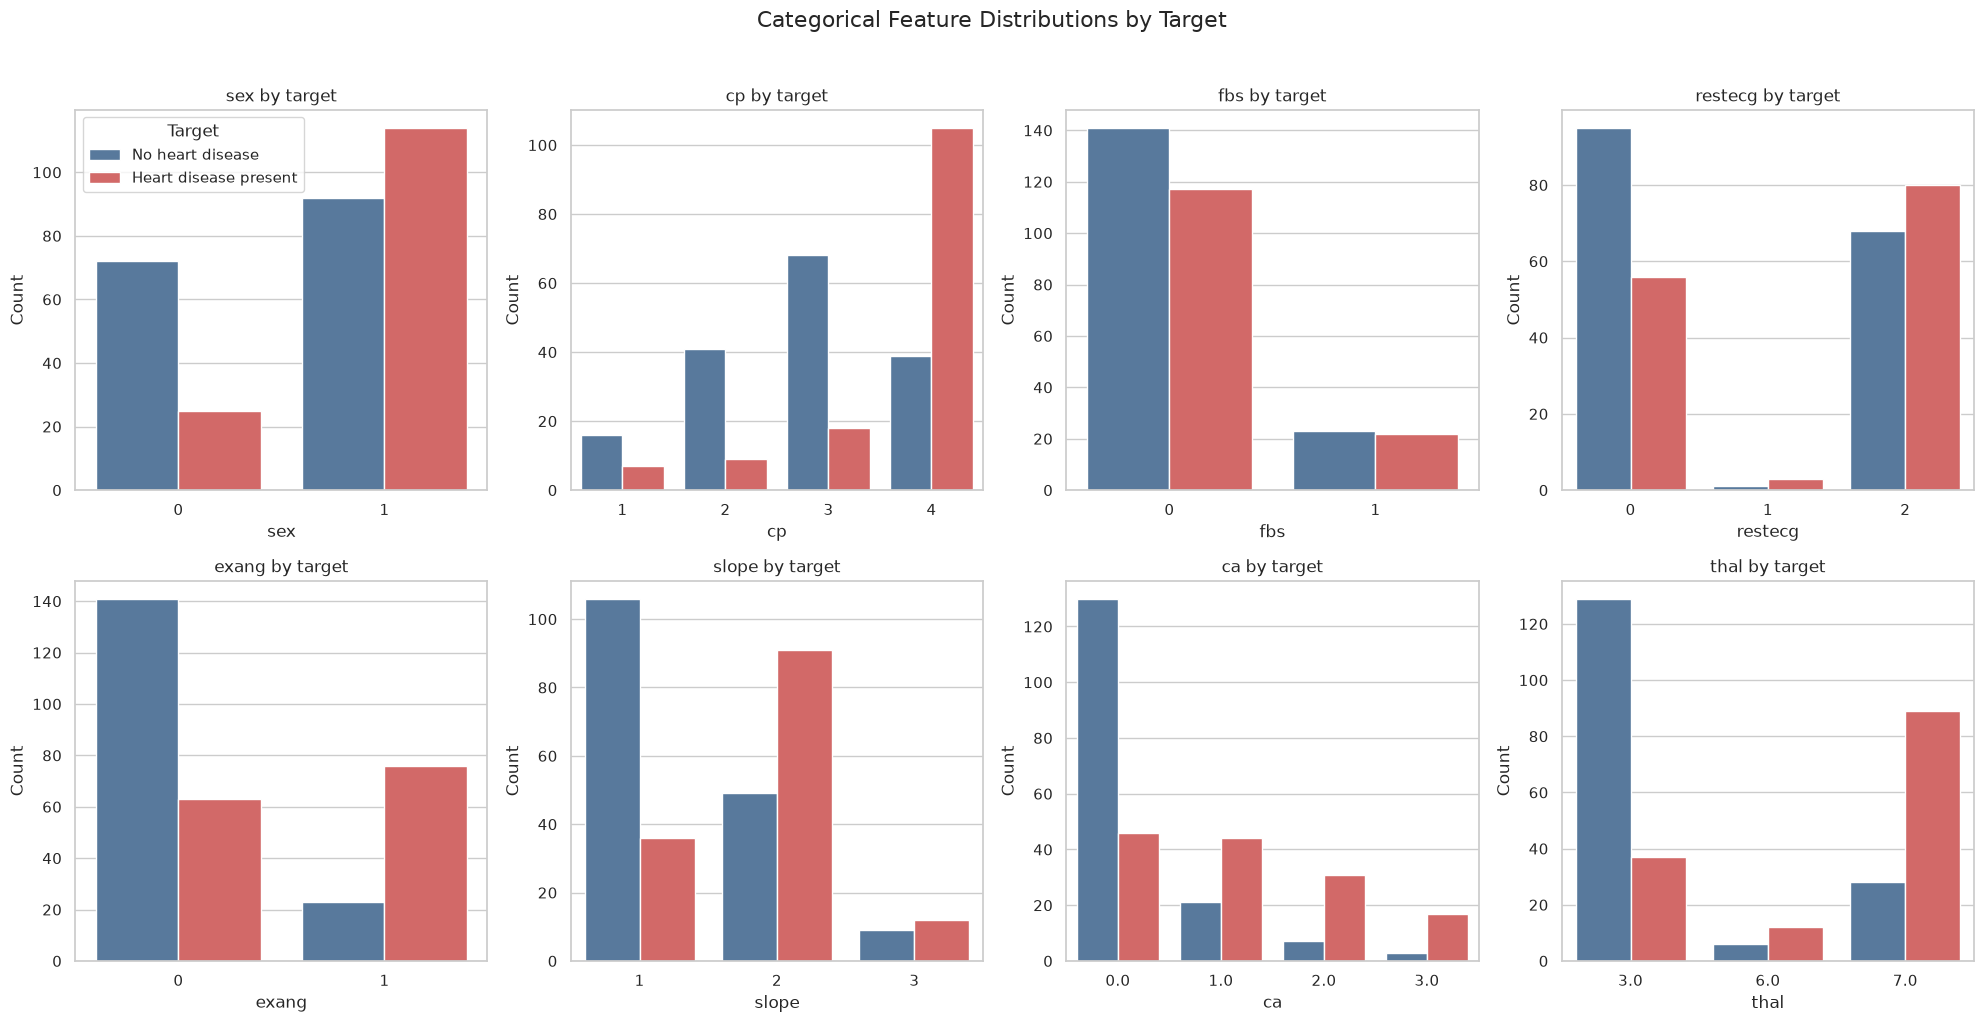

Figure saved to: /workspaces/MLOPS_Assignment/reports/figures/categorical_feature_distributions.png


In [20]:
categorical_features = [
    "sex",
    "cp",
    "fbs",
    "restecg",
    "exang",
    "slope",
    "ca",
    "thal",
]

fig, axes = plt.subplots(
    nrows=2,
    ncols=4,
    figsize=(20, 10),
)

axes = axes.flatten()

for index, feature in enumerate(categorical_features):
    sns.countplot(
        data=clean_df,
        x=feature,
        hue="target",
        palette=["#4C78A8", "#E45756"],
        ax=axes[index],
    )

    axes[index].set_title(f"{feature} by target")
    axes[index].set_xlabel(feature)
    axes[index].set_ylabel("Count")
    axes[index].tick_params(
        axis="x",
        rotation=0,
    )

    if index != 0:
        legend = axes[index].get_legend()
        if legend is not None:
            legend.remove()

axes[0].legend(
    title="Target",
    labels=[
        "No heart disease",
        "Heart disease present",
    ],
)

plt.suptitle(
    "Categorical Feature Distributions by Target",
    fontsize=16,
    y=1.02,
)

plt.tight_layout()

categorical_plot_path = (
    FIGURES_DIR / "categorical_feature_distributions.png"
)

plt.savefig(
    categorical_plot_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print(f"Figure saved to: {categorical_plot_path}")

In [21]:
for feature in categorical_features:
    feature_summary = (
        clean_df
        .groupby(feature, dropna=False)["target"]
        .agg(
            observation_count="count",
            heart_disease_rate="mean",
        )
        .reset_index()
    )

    feature_summary["heart_disease_rate"] = (
        feature_summary["heart_disease_rate"] * 100
    ).round(2)

    print(f"\nHeart disease rate by {feature}:")
    display(feature_summary)


Heart disease rate by sex:


,sex,observation_count,heart_disease_rate
0,0,97,25.770
1,1,206,55.340



Heart disease rate by cp:


,cp,observation_count,heart_disease_rate
0,1,23,30.430
1,2,50,18.000
2,3,86,20.930
3,4,144,72.920



Heart disease rate by fbs:


...

,slope,observation_count,heart_disease_rate
0,1,142,25.350
1,2,140,65.000
2,3,21,57.140



Heart disease rate by ca:


,ca,observation_count,heart_disease_rate
0,0.000,176,26.140
1,1.000,65,67.690
2,2.000,38,81.580
3,3.000,20,85.000
4,NaN,4,25.000



Heart disease rate by thal:


,thal,observation_count,heart_disease_rate
0,3.000,166,22.290
1,6.000,18,66.670
2,7.000,117,76.070
3,NaN,2,50.000


### Categorical-feature observations

The categorical plots indicate that the proportion of positive and negative target cases varies across several categories. Features such as chest-pain type (`cp`), exercise-induced angina (`exang`), major-vessel count (`ca`), and thalassemia-related category (`thal`) may provide useful predictive information.

Because these columns represent category codes rather than continuous measurements, they will be treated as categorical features and one-hot encoded in the model pipeline.

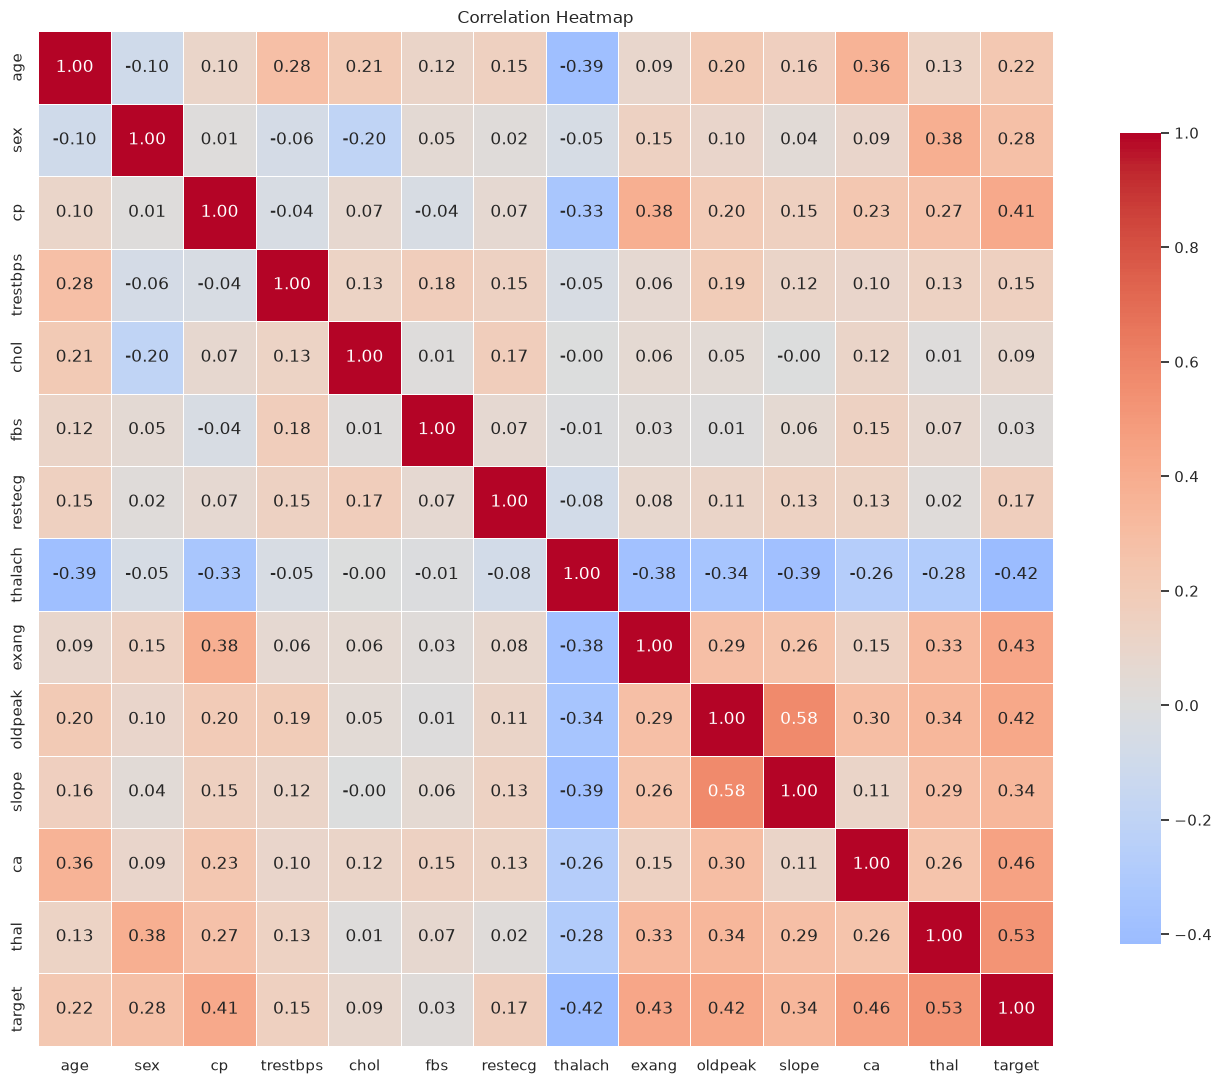

Figure saved to: /workspaces/MLOPS_Assignment/reports/figures/correlation_heatmap.png


In [22]:
correlation_matrix = clean_df.corr(numeric_only=True)

plt.figure(figsize=(14, 11))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8},
)

plt.title("Correlation Heatmap")
plt.tight_layout()

correlation_plot_path = FIGURES_DIR / "correlation_heatmap.png"

plt.savefig(
    correlation_plot_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print(f"Figure saved to: {correlation_plot_path}")

In [23]:
target_correlations = (
    correlation_matrix["target"]
    .drop("target")
    .sort_values(
        key=lambda values: values.abs(),
        ascending=False,
    )
    .to_frame(name="correlation_with_target")
)

display(target_correlations)

,correlation_with_target
thal,0.526
ca,0.460
exang,0.432
oldpeak,0.425
thalach,-0.417
cp,0.414
slope,0.339
sex,0.277
age,0.223
restecg,0.169


In [24]:
predictor_correlation_matrix = (
    correlation_matrix
    .drop(index="target", columns="target")
)

upper_triangle = predictor_correlation_matrix.where(
    np.triu(
        np.ones(predictor_correlation_matrix.shape),
        k=1,
    ).astype(bool)
)

strong_correlation_pairs = (
    upper_triangle
    .stack()
    .reset_index()
)

strong_correlation_pairs.columns = [
    "feature_1",
    "feature_2",
    "correlation",
]

strong_correlation_pairs = (
    strong_correlation_pairs[
        strong_correlation_pairs["correlation"].abs() >= 0.70
    ]
    .sort_values(
        "correlation",
        key=lambda values: values.abs(),
        ascending=False,
    )
)

if strong_correlation_pairs.empty:
    print(
        "No predictor pairs have an absolute correlation "
        "greater than or equal to 0.70."
    )
else:
    display(strong_correlation_pairs)

No predictor pairs have an absolute correlation greater than or equal to 0.70.


### Correlation observations

The correlation analysis identifies variables with relatively stronger linear associations with the binary target. Correlation values should be interpreted as descriptive associations rather than causal effects.

The heatmap also helps identify highly correlated predictor pairs. No feature will be removed solely because of its correlation with the target. Logistic Regression will use scaling and regularization, while Random Forest can model non-linear relationships and feature interactions.

In [25]:
def calculate_iqr_outlier_summary(
    dataframe: pd.DataFrame,
    columns: list[str],
) -> pd.DataFrame:
    records = []

    for column in columns:
        series = dataframe[column].dropna()

        q1 = series.quantile(0.25)
        q3 = series.quantile(0.75)
        iqr = q3 - q1

        lower_bound = q1 - (1.5 * iqr)
        upper_bound = q3 + (1.5 * iqr)

        outlier_count = (
            (series < lower_bound)
            | (series > upper_bound)
        ).sum()

        records.append(
            {
                "feature": column,
                "lower_bound": lower_bound,
                "upper_bound": upper_bound,
                "potential_outlier_count": int(outlier_count),
                "potential_outlier_percentage": round(
                    100 * outlier_count / len(series),
                    2,
                ),
            }
        )

    return pd.DataFrame(records)


outlier_summary = calculate_iqr_outlier_summary(
    clean_df,
    numerical_features,
)

display(outlier_summary)

,feature,lower_bound,upper_bound,potential_outlier_count,potential_outlier_percentage
0,age,28.500,80.500,0,0.000
1,trestbps,90.000,170.000,9,2.970
2,chol,115.000,371.000,5,1.650
3,thalach,84.750,214.750,1,0.330
4,oldpeak,-2.400,4.000,5,1.650


### Potential-outlier observation

The interquartile-range method identifies observations that are statistically distant from the central distribution. These records are not removed automatically because unusual clinical measurements may be genuine observations rather than data-entry errors.

The retained observations will allow the models to learn from the complete dataset. Standard scaling will be applied to numerical variables within the Logistic Regression pipeline.

In [26]:
clean_df.to_csv(
    PROCESSED_DATA_PATH,
    index=False,
)

print(f"Cleaned dataset saved to: {PROCESSED_DATA_PATH}")
print(f"Saved shape: {clean_df.shape}")
print(f"Saved columns: {clean_df.columns.tolist()}")

Cleaned dataset saved to: /workspaces/MLOPS_Assignment/data/processed/heart_disease_cleaned.csv
Saved shape: (303, 14)
Saved columns: ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']


In [27]:
data_quality_summary = pd.DataFrame(
    {
        "measure": [
            "Number of rows",
            "Number of predictor features",
            "Number of target columns",
            "Exact duplicate rows after cleaning",
            "Total missing predictor values",
            "Negative target observations",
            "Positive target observations",
        ],
        "value": [
            len(clean_df),
            clean_df.drop(columns="target").shape[1],
            1,
            int(clean_df.duplicated().sum()),
            int(
                clean_df
                .drop(columns="target")
                .isna()
                .sum()
                .sum()
            ),
            int((clean_df["target"] == 0).sum()),
            int((clean_df["target"] == 1).sum()),
        ],
    }
)

display(data_quality_summary)

quality_summary_path = (
    PROCESSED_DATA_DIR / "data_quality_summary.csv"
)

data_quality_summary.to_csv(
    quality_summary_path,
    index=False,
)

print(f"Quality summary saved to: {quality_summary_path}")

,measure,value
0,Number of rows,303
1,Number of predictor features,13
2,Number of target columns,1
3,Exact duplicate rows after cleaning,0
4,Total missing predictor values,6
5,Negative target observations,164
6,Positive target observations,139


Quality summary saved to: /workspaces/MLOPS_Assignment/data/processed/data_quality_summary.csv


## 5. EDA conclusion

The dataset was acquired programmatically from the UCI Machine Learning Repository and preserved in its original combined form. The original diagnosis target was converted into a binary target representing the absence or presence of heart disease.

The exploratory analysis covered:

- Dataset structure and descriptive statistics
- Duplicate observations
- Missing-value patterns
- Binary target balance
- Numerical-feature distributions
- Categorical-feature distributions
- Correlation patterns
- Potential numerical outliers

Missing predictor values were intentionally retained because imputation will be performed within the model preprocessing pipeline. This prevents information leakage from the test set into the training process.

The processed dataset is ready for model development using:

1. Logistic Regression as an interpretable baseline
2. Random Forest as a non-linear comparison model
3. Stratified train-test splitting
4. Stratified cross-validation
5. Limited hyperparameter tuning
6. MLflow experiment tracking
7. Accuracy, precision, recall, F1-score, and ROC-AUC evaluation

This project is an educational MLOps demonstration and is not intended for clinical diagnosis.